# Demixing index (50:50) vs charge patterning (SCD)

Standalone plot of the two-component demixing index D at the 50:50 composition against each
partner's charge patterning (SCD), in the same style as the Tc-vs-D figure: partners are split
into **sub-critical** (Tc > 298 K, phase-separate on their own) and **super-critical**
(Tc < 298 K, do not), each with its own fit line and Pearson r; markers are coloured by SCD.

**Run from inside the `Figure5` folder.** D and SCD are read from `analysis_37377.out` via
`fig5_io.load()`; the single-component Tc (used only to assign the two groups) is embedded.

## Setup

In [1]:
import os
import numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import linregress

plt.rcParams.update({
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'font.family': 'sans-serif', 'font.size': 11,
    'axes.titlesize': 12.5, 'axes.labelsize': 12,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'axes.linewidth': 1.0, 'mathtext.default': 'regular',
})

## Load D and SCD (analysis_37377.out) and assign sub / super-critical groups by Tc

In [2]:
from fig5_io import load
M = load()

TC = {'P1': 339.08, 'P2': 328.67, 'P3': 331.64, 'P4': 339.85, 'P5': 323.79,
      'P6': 312.42, 'P7': 328.67, 'P8': 317.78, 'P9': 312.49, 'P10': 311.84,
      'P11': 302.85, 'P12': 312.05, 'P13': 277.46, 'P14': 274.37, 'P15': 283.52,
      'WT': 282.60, 'V1': 302.60, 'V3': 319.90}
M['Tc'] = M['label'].map(TC)

s50 = M[M.pct == 50].copy()
TSIM = 298.0
NON_PS = ['WT', 'P13', 'P14', 'P15']              # super-critical (Tc < 298 K)
s50['group'] = np.where(s50['Tc'] < TSIM, 'super', 'sub')
print('super-critical (Tc<298):', sorted(s50[s50.group=='super'].label),
      '| sub-critical (Tc>298):', len(s50[s50.group=='sub']))

super-critical (Tc<298): ['P13', 'P14', 'P15', 'WT'] | sub-critical (Tc>298): 14


## Plot — D(50:50) vs SCD, sub- and super-critical partners

saved SCD_vs_demixing  | r super=0.76  sub=-0.15


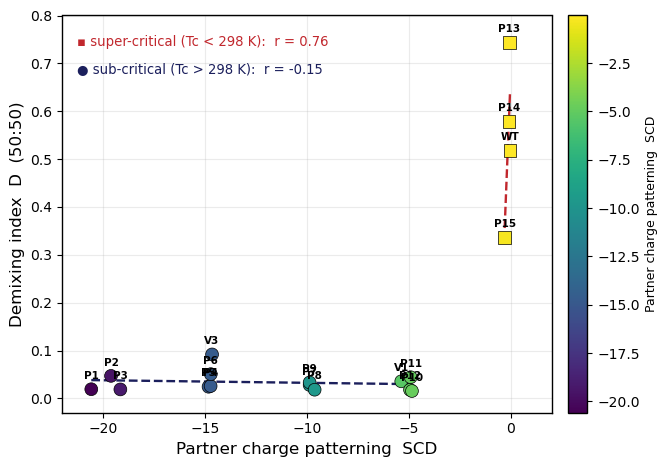

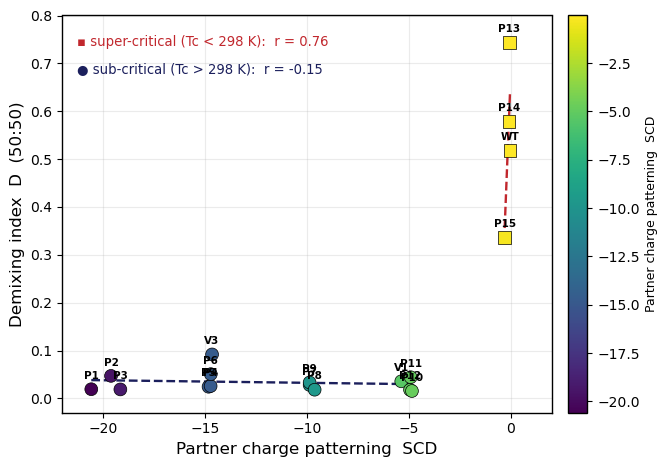

In [4]:
scd_norm = mpl.colors.Normalize(vmin=M.SCD.min(), vmax=M.SCD.max())
scd_cmap = plt.cm.viridis

def add_fit(ax, x, y, color, lw=1.7):
    x = np.asarray(x, float); y = np.asarray(y, float)
    if len(x) < 2 or np.ptp(x) == 0:
        return np.nan
    lr = linregress(x, y)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, lr.intercept + lr.slope * xs, '--', color=color, lw=lw, zorder=2)
    return lr.rvalue

fig, ax = plt.subplots(figsize=(6.8, 4.8))

# (group key, label, marker, fit colour)
specs = [
    ('super', 'super-critical  (Tc < 298 K, no self-LLPS)', 's', '#c1272d'),
    ('sub',   'sub-critical  (Tc > 298 K, self-LLPS)',      'o', '#1b1f5c'),
]
rvals = {}
for key, name, mk, fc in specs:
    d = s50[s50.group == key]
    ax.scatter(d.SCD, d.D, s=85, marker=mk, c=d.SCD, cmap=scd_cmap, norm=scd_norm,
               edgecolors='k', linewidths=0.5, zorder=3)
    rvals[key] = add_fit(ax, d.SCD, d.D, fc)

for row in s50.itertuples():
    ax.annotate(row.label, (row.SCD, row.D), fontsize=7.5, fontweight='bold',
                ha='center', va='bottom', xytext=(0, 6), textcoords='offset points')

ax.text(0.03, 0.95, f'▪ super-critical (Tc < 298 K):  r = {rvals["super"]:.2f}',
        transform=ax.transAxes, color='#c1272d', ha='left', va='top', fontsize=9.5)
ax.text(0.03, 0.88, f'● sub-critical (Tc > 298 K):  r = {rvals["sub"]:.2f}',
        transform=ax.transAxes, color='#1b1f5c', ha='left', va='top', fontsize=9.5)

ax.set_xlim(-22, 2); ax.set_ylim(-0.03, 0.80)
ax.set_xlabel('Partner charge patterning  SCD')
ax.set_ylabel('Demixing index  D  (50:50)')
#ax.set_title('Demixing (50:50) vs charge patterning (SCD)', loc='left', fontweight='bold')
ax.grid(alpha=0.25)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=scd_norm, cmap=scd_cmap), ax=ax,
                  fraction=0.046, pad=0.03)
cb.set_label('Partner charge patterning  SCD', fontsize=9)

fig.tight_layout()
fig.savefig('SCD_vs_demixing.pdf', dpi=300, bbox_inches='tight')
fig.savefig('SCD_vs_demixing.png', dpi=300, bbox_inches='tight')
print('saved SCD_vs_demixing  | r super=%.2f  sub=%.2f' % (rvals['super'], rvals['sub']))
fig